In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset.csv")
print(df.head())
print("Dataset shape: ", df.shape)
print(df.columns.tolist)

     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com            24           0  com   
1            www.uni-mainz.de            16           0   de   
2      www.voicefmradio.co.uk            22           0   uk   
3         www.sfnmjournal.com            19           0  com   
4  www.rewildingargentina.org            26           0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...    0   
1               100.0              0.666667           0.032650  ...    0   
2 

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    RocCurveDisplay
)

In [18]:
df=pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset.csv")

In [19]:
print("Dataset shape: ", df.shape)
print("Missing values: ",df.isnull().sum())
print("\nOriginal class distribution:")
print(df["label"].value_counts())

Dataset shape:  (235795, 56)
Missing values:  FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                     

In [20]:
df = df.dropna(subset=["label"]).copy()

y = (df["label"]==0).astype(int)

X=df.drop(
    columns=["label", "URL", "Domain", "TLD", "Title"],
    errors="ignore"
)

X = X.select_dtypes(include=np.number).copy()

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("\nFeatures: ", X.shape)
print("Target distribution: ")
print(y.value_counts())


Features:  (235795, 50)
Target distribution: 
label
0    134850
1    100945
Name: count, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [22]:
print("\nTraining samples: ",len(X_train))
print("\nTesting samplpes: ",len(X_test))


Training samples:  188636

Testing samplpes:  47159


In [23]:
model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)

model.fit(X_train, y_train)
print("\nSVM model trained successfully!")


SVM model trained successfully!


In [24]:
y_pred = model.predict(X_test)

y_score = model.decision_function(X_test)

print("\nFirst 10 actual labels: ")
print(y_test.iloc[:10].values)

print("\nFirst 10predicted labels: ")
print(y_pred[:10])


First 10 actual labels: 
[0 1 0 1 0 0 1 1 0 0]

First 10predicted labels: 
[0 1 0 1 0 0 1 1 0 0]



Confusion Matrix: 
[[26970     0]
 [    0 20189]]


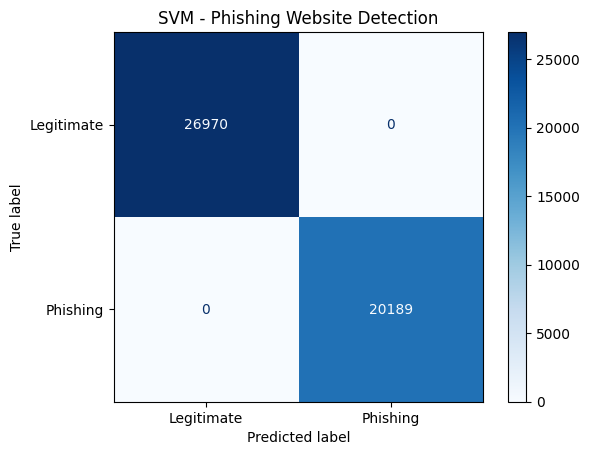

In [25]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0,1]
)

print("\nConfusion Matrix: ")
print(cm)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
).plot(cmap="Blues", values_format="d")

plt.title("SVM - Phishing Website Detection")
plt.show()

In [26]:
precision = precision_score(
    y_test, y_pred,zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_score)

print("\n====Model Performance ====")
print(f"Precision :{precision:.4f}")
print(f"Recall    :{recall:.4f}")
print(f"F1-score  :{f1:.4f}")
print(f"ROC-AUC :{roc_auc:.4f}")


print("\nClassification Report: ")
print(
    classification_report(
        y_test,y_pred, labels=[0,1],target_names=["Legitimate", "Phishing"],zero_division=0
    )
)


====Model Performance ====
Precision :1.0000
Recall    :1.0000
F1-score  :1.0000
ROC-AUC :1.0000

Classification Report: 
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20189

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159



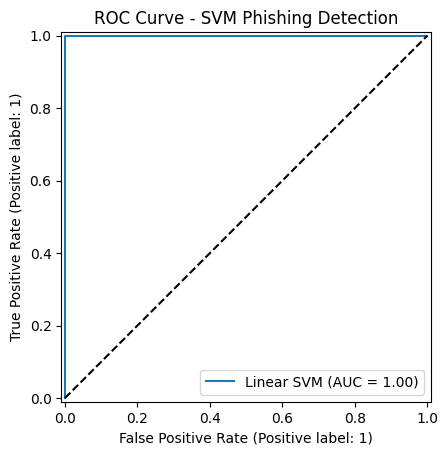

In [27]:
RocCurveDisplay.from_predictions(
    y_test, y_score, name="Linear SVM"
)

plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curve - SVM Phishing Detection")
plt.show()